# Chapter 2: Of those we flagged, of those we missed: which question does each ratio answer?

*Precision, recall and F1 derived · also searched as: precision vs recall, F1 score, harmonic mean*

**Who needs the answer.** Kalpa Retail's Marketing team, who ask "when we nudge, how often does it land?", and Anand in Finance, who asks "how many repeaters did we fail to reach?". They are two different questions with two different denominators.

**The questions on the way.** Of the customers flagged, what share came back? Of the customers who came back, what share were flagged? Why is F1 a harmonic mean and not the plain average? What wrong denominator do people reach for first?

You will be able to compute precision, recall and F1 from any four counts, say each as a sentence, and spot the wrong denominator in someone else's number.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

import numpy as np
# Chapter 1's four boxes on the twenty invented Kalpa customers.
TP, FP, FN, TN = 3, 3, 2, 12
print(f"TP {TP}, FP {FP}, FN {FN}, TN {TN}: {TP + FP + FN + TN} customers, {TP + FP} flagged, {TP + FN} real repeaters")

TP 3, FP 3, FN 2, TN 12: 20 customers, 6 flagged, 5 real repeaters


## Of those we flagged, how many came back? Of those who came back, how many did we flag?

**Predict before you run.** Which is larger here, the share of flags that landed or the share of repeaters found? (a) the share of flags that landed, (b) the share of repeaters found, (c) they are equal.

In [2]:
precision = TP / (TP + FP)        # of those we flagged
recall = TP / (TP + FN)           # of those who came back
print(f"precision: {TP} of {TP + FP} flagged came back = {precision:.2f}")
print(f"recall:    {TP} of {TP + FN} repeaters were flagged = {recall:.2f}")

precision: 3 of 6 flagged came back = 0.50
recall:    3 of 5 repeaters were flagged = 0.60


**What happened.** The answer is (b): precision is 3 of 6, 0.50, and recall is 3 of 5, 0.60. Both share the same numerator, the three true positives. Precision divides by the column of flags, recall by the row of real repeaters.

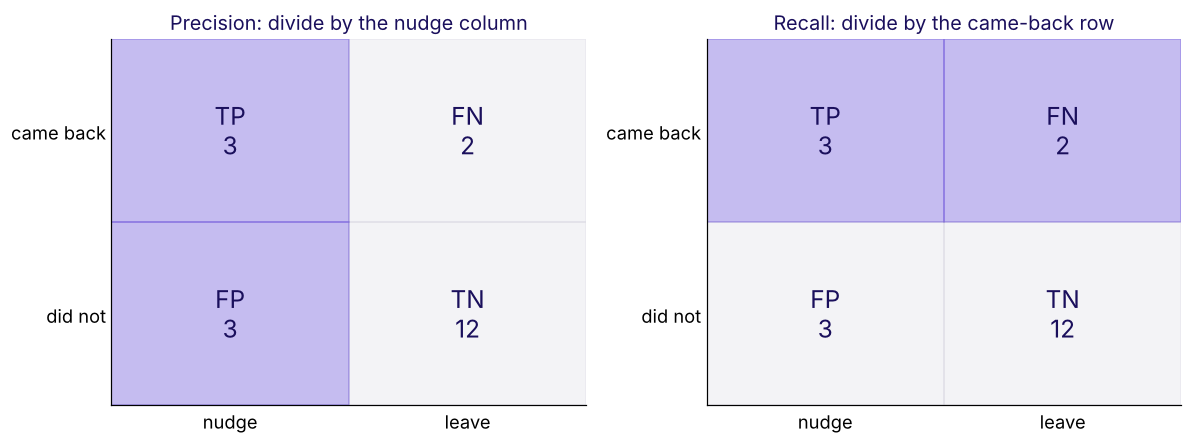

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, title, hi in ((axes[0], "Precision: divide by the nudge column", "col"), (axes[1], "Recall: divide by the came-back row", "row")):
    vals = [[TP, FN], [FP, TN]]; names = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            lit = (hi == "col" and j == 0) or (hi == "row" and i == 0)
            ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=VIOLET if lit else MUTED, alpha=0.35 if lit else 0.08))
            ax.text(j + 0.5, 1.5 - i, f"{names[i][j]}\n{vals[i][j]}", ha="center", va="center", fontsize=16, color=INK)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["nudge", "leave"])
    ax.set_yticks([1.5, 0.5]); ax.set_yticklabels(["came back", "did not"]); ax.tick_params(length=0); ax.set_title(title, color=INK)
plt.tight_layout(); plt.show()

## Why is F1 the harmonic mean?

A single number is often asked for. F1 joins precision and recall with the harmonic mean, which stays low when either one is low. Take an invented model B that flags one customer and is right: precision 1.0, recall 0.2 on five repeaters. The plain average says 0.60 and sounds fine; F1 says 0.33, which is the honest grade for a model that found one repeater in five.

our model: precision 0.50, recall 0.60, plain mean 0.55, F1 0.55
model B:   precision 1.00, recall 0.20, plain mean 0.60, F1 0.33


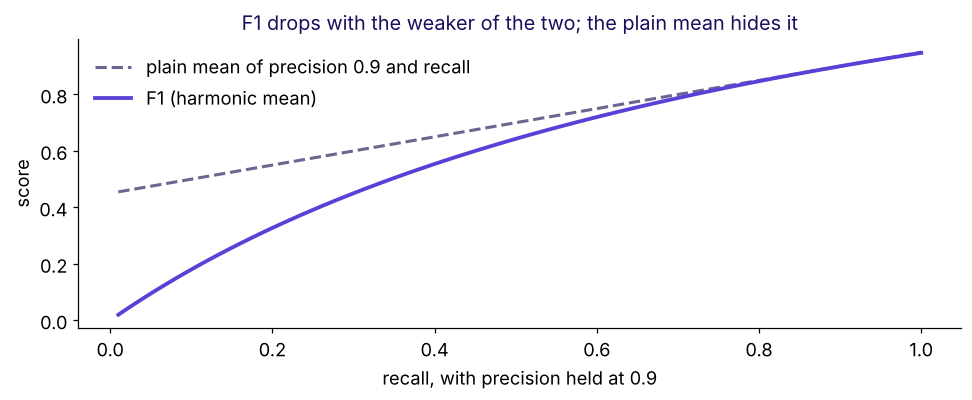

In [4]:
def f1(p, r): return 2 * p * r / (p + r) if p + r else 0.0
print(f"our model: precision {precision:.2f}, recall {recall:.2f}, plain mean {(precision + recall) / 2:.2f}, F1 {f1(precision, recall):.2f}")
print(f"model B:   precision 1.00, recall 0.20, plain mean {(1 + 0.2) / 2:.2f}, F1 {f1(1, 0.2):.2f}")
r = np.linspace(0.01, 1, 100)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(r, (0.9 + r) / 2, color=MUTED, ls="--", lw=2, label="plain mean of precision 0.9 and recall")
ax.plot(r, [f1(0.9, x) for x in r], color=VIOLET, lw=2.5, label="F1 (harmonic mean)")
ax.set_xlabel("recall, with precision held at 0.9"); ax.set_ylabel("score"); ax.legend(frameon=False)
ax.set_title("F1 drops with the weaker of the two; the plain mean hides it", color=INK); plt.tight_layout(); plt.show()

## The trap: which denominator do people reach for first?

The common wrong answer divides by everyone: **"precision is 3 of 20, 0.15."** That is the share of all customers who were flagged and came back, which nobody asked for. Marketing would conclude its nudges land 15 percent of the time and cut a campaign whose flags land 50 percent of the time. The check: precision's denominator must equal the number flagged. The fix: say the sentence first, "of those we flagged", and the denominator follows.

In [5]:
wrong = TP / (TP + FP + FN + TN)
print(f"the wrong denominator gives {wrong:.2f}; the right one gives {precision:.2f}")
from sklearn.metrics import precision_score, recall_score, f1_score
truth = [1] * TP + [0] * FP + [1] * FN + [0] * TN
pred = [1] * TP + [1] * FP + [0] * FN + [0] * TN
print("PASS  scikit-learn's precision agrees" if np.isclose(precision_score(truth, pred), precision) else "CHECK precision")
print("PASS  scikit-learn's recall agrees" if np.isclose(recall_score(truth, pred), recall) else "CHECK recall")
print("PASS  scikit-learn's F1 agrees" if np.isclose(f1_score(truth, pred), f1(precision, recall)) else "CHECK F1")

the wrong denominator gives 0.15; the right one gives 0.50


PASS  scikit-learn's precision agrees
PASS  scikit-learn's recall agrees
PASS  scikit-learn's F1 agrees


## What did this chapter establish?

| Ratio | The question it answers | Formula | Here |
|---|---|---|---|
| Precision | Of those we flagged, how many were right? | `TP / (TP + FP)` | 3 / 6 = 0.50 |
| Recall | Of those who were real, how many did we flag? | `TP / (TP + FN)` | 3 / 5 = 0.60 |
| F1 | One grade that stays low if either is low | `2 x P x R / (P + R)` | 0.55 |

**The rule.** Pick the ratio by the question the business asks. F1 weighs the two errors as equal, so it stops being the right single number the moment one error costs more than the other.

**In the interview.** "Precision or recall for fraud, and why?" Name what a missed fraud costs and what a false block costs, then pick.

Chapter 3 asks what accuracy, the ratio everyone starts with, hides.